In [7]:
#import lib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df=pd.read_csv(r"/content/europe.csv")

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              36 non-null     int64  
 1   country_name            36 non-null     object 
 2   Continent               36 non-null     object 
 3   region                  36 non-null     object 
 4   local_name              36 non-null     object 
 5   capital                 36 non-null     object 
 6   area                    36 non-null     object 
 7   population              36 non-null     object 
 8   population_per_sq_km    36 non-null     object 
 9   male_life_expectancy    36 non-null     float64
 10  female_life_expectancy  36 non-null     float64
 11  birth_rate              36 non-null     float64
 12  death_rate              36 non-null     float64
dtypes: float64(4), int64(1), object(8)
memory usage: 3.8+ KB


In [10]:
df = df.drop(columns=['Unnamed: 0'])
df.sample(10)

,country_name,Continent,region,local_name,capital,area,population,population_per_sq_km,male_life_expectancy,female_life_expectancy,birth_rate,death_rate
31,Montenegro,Europe,Southern Europe,Црна Гора / Crna Gora / Mali i Zi,Podgorica,"13,810 km²","621,306",44.99,73.2,78.8,11.4,11.7
28,Albania,Europe,Southern Europe,Republika e Shqipërisë,Tirana,"28,750 km²","2,838,000",98.71,77.2,80.3,11.5,8.3
25,Norway,Europe,Northern Europe,Norge,Oslo,"385,203 km²","5,379,000",13.97,81.6,84.9,9.8,7.5
0,Austria,Europe,Western Europe,Österreich,Vienna,"83,879 km²","8,917,000",106.3,78.9,83.6,9.4,10.3
10,Czechia,Europe,Eastern Europe,Czech Republic,"Česko, Česká republika","78,870 km²","10,698,000",135.6,75.3,81.3,10.3,12.1
23,Latvia,Europe,Northern Europe,Latvija,Riga,"64,490 km²","1,900,000",29.47,70.9,80.1,9.2,15.2
4,Liechtenstein,Europe,Western Europe,Liechtenstein,Vaduz,161 km²,"38,137",237.6,80.1,83.6,9.1,8.2
13,Poland,Europe,Eastern Europe,Polska,Warsaw,"312,680 km²","37,899,000",121.2,72.6,80.8,9.4,12.6
1,Belgium,Europe,Western Europe,België / Belgique,Brussels,"30,530 km²","11,544,000",378.1,78.6,83.1,9.9,11.0
29,Greece,Europe,Southern Europe,Ελλάδα / Elláda,Athens,"131,960 km²","10,701,000",81.09,78.6,83.7,7.9,12.2


In [11]:
df.isna().sum()
df.duplicated().sum()


np.int64(0)

In [12]:
def area_correct(value):
  if pd.isna(value):
    return value
  clean_val = str(value).split(" ")[0]

  clean_val = clean_val.replace(",", "")
  return int(clean_val)

df["area"] = df["area"].apply(area_correct)
df["area"].dtype

dtype('int64')

In [13]:
def correct_pop(value):
  clean_val=str(value)
  clean_val=clean_val.replace(",","")
  return int(clean_val)
df["population"]=df["population"].apply(correct_pop)
df["population"].dtype



dtype('int64')

In [14]:
def correct_pop_per(value):
  clean_val=str(value)
  marks=[",","."]
  for mark in marks:
    clean_val=clean_val.replace(mark,"")
  return int(clean_val)
df["population_per_sq_km"]=df["population_per_sq_km"].apply(correct_pop_per)
df["population_per_sq_km"].dtype


dtype('int64')

In [15]:
df.dtypes
df["Continent"].count()
df.describe(include="O")
df=df.drop(columns=["Continent"])
df.sample(10)

,country_name,region,local_name,capital,area,population,population_per_sq_km,male_life_expectancy,female_life_expectancy,birth_rate,death_rate
21,Iceland,Northern Europe,Ísland,Reykjavík,103000,366463,3558,81.7,84.5,12.3,6.3
18,Denmark,Northern Europe,Danmark,Copenhagen,42920,5831000,1359,79.6,83.6,10.4,9.4
24,Lithuania,Northern Europe,Lietuva,Vilnius,65286,2795000,4281,70.1,80.0,9.0,15.6
1,Belgium,Western Europe,België / Belgique,Brussels,30530,11544000,3781,78.6,83.1,9.9,11.0
35,Spain,Southern Europe,España,Madrid,505935,47363000,9362,79.7,85.1,7.1,10.4
17,Ukraine,Eastern Europe,Ukrajina / Україна,Kiev,603550,44135000,7313,66.4,76.2,7.8,15.9
30,Malta,Southern Europe,Malta,Valletta,320,515332,1610,80.8,84.6,8.6,7.9
34,Slovenia,Southern Europe,Slovenija,Ljubljana,20675,2102000,1017,77.8,83.4,8.9,11.4
8,Belarus,Eastern Europe,Weißrussland,Беларусь,207600,9380000,4518,69.3,79.4,9.3,13.0
12,Moldova,Eastern Europe,Moldau,Moldova,33850,2620000,7741,67.7,76.3,9.8,11.8


['area', 'population', 'population_per_sq_km', 'male_life_expectancy', 'female_life_expectancy', 'birth_rate', 'death_rate']


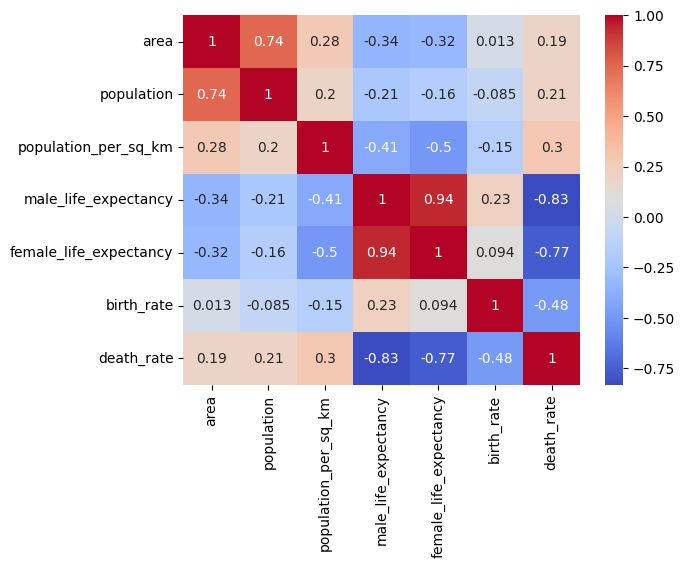

In [16]:
numeroc=df.select_dtypes(include=["int64","float64"]).columns.tolist()
print(numeroc)
corr=df[numeroc].corr()
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.show()

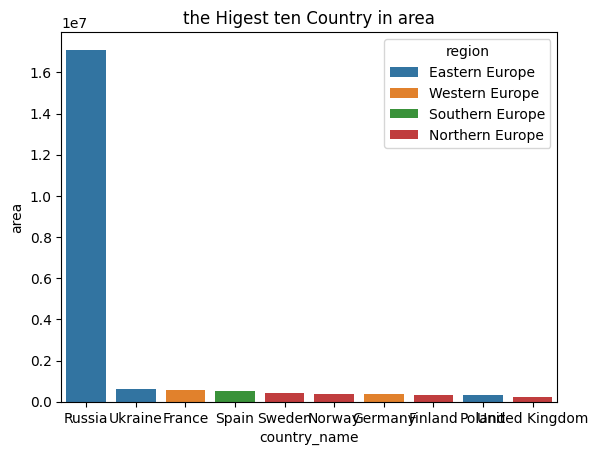

In [18]:
#the biggest ten area places country,region
higehest_ten=df.sort_values(by="area",ascending=False).head(10)
df.loc[higehest_ten.index,["country_name","region","area"]]
sns.barplot(data=higehest_ten,x="country_name",y="area",hue="region")
plt.title("the Higest ten Country in area")
plt.show()



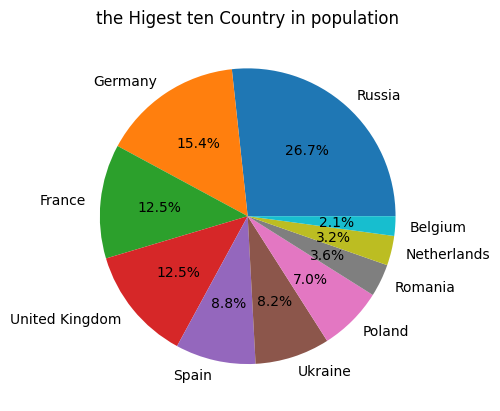

In [19]:
#the biggest ten population places
highet_ten_pop=df.sort_values(by="population",ascending=False).head(10)
df.loc[highet_ten_pop.index,["country_name","population","region"]]
plt.pie(highet_ten_pop["population"],labels=highet_ten_pop["country_name"],autopct="%1.1f%%")
plt.title("the Higest ten Country in population")
plt.show()


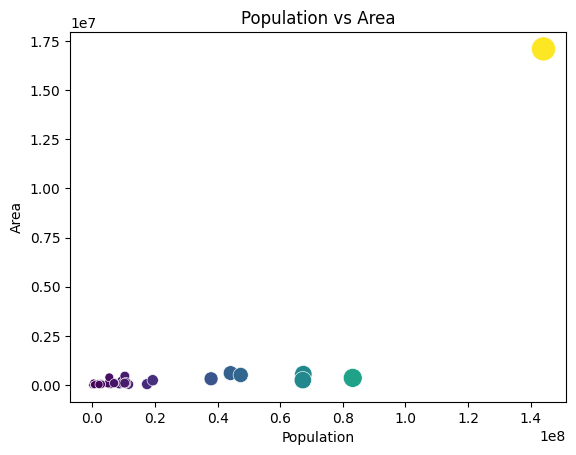

In [20]:
#the most populations
sns.scatterplot(
    data=df,
    x="population",
    y="area",
    size="population",
    hue="population",
    sizes=(30, 300),
    palette="viridis",
    legend=False
)

plt.title("Population vs Area")
plt.xlabel("Population")
plt.ylabel("Area")
plt.show()



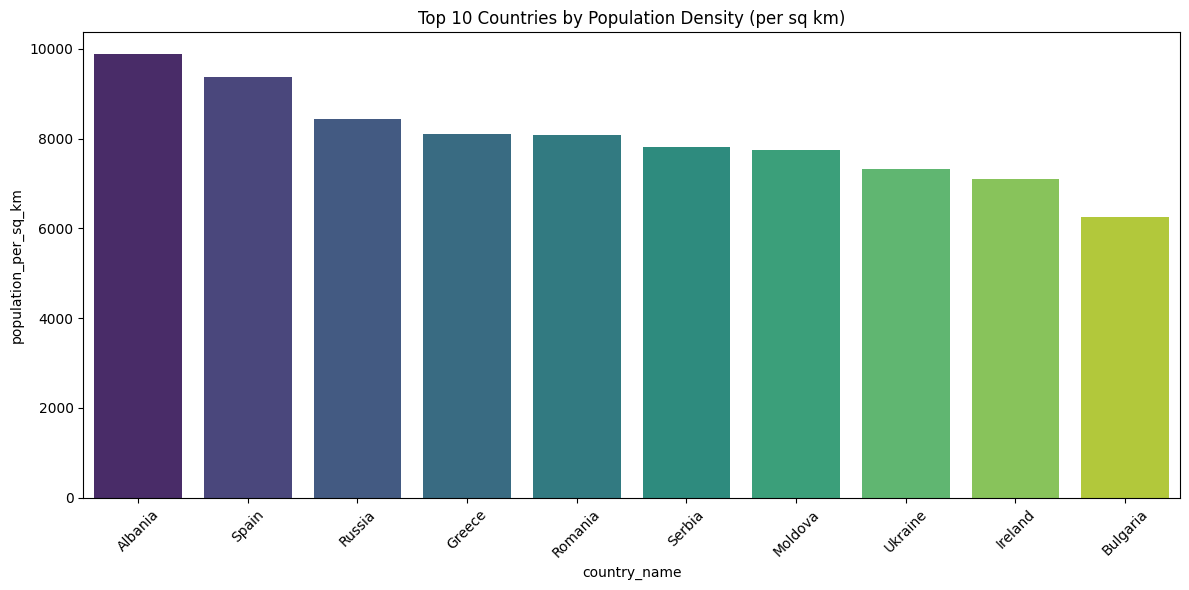

In [29]:
#Most ten pop per
most_ten=df.sort_values(by="population_per_sq_km",ascending=False).head(10)
df.loc[most_ten.index,["country_name","population_per_sq_km","area"]]

# Using a bar plot to compare the population density of the top 10 countries instead of KDE
plt.figure(figsize=(12, 6))
sns.barplot(
    data=most_ten,
    x="country_name",
    y="population_per_sq_km",
    hue="country_name",
    palette="viridis",
    legend=False
)
plt.title("Top 10 Countries by Population Density (per sq km)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


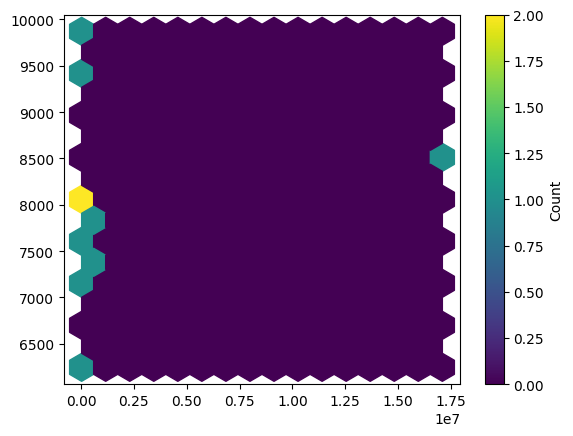

In [31]:
plt.hexbin(
    most_ten["area"],
    most_ten["population_per_sq_km"],
    gridsize=15,
    cmap="viridis"
)
plt.colorbar(label="Count")
plt.show()

In [33]:
import plotly.express as px

fig = px.bar(
    df,
    x="country_name",
    y=["female_life_expectancy", "male_life_expectancy"],
    barmode="group",
    title="Life Expectancy: Female vs Male by Country",
    labels={
        "country_name": "Country",
        "value": "Life Expectancy (Years)",
        "variable": "Gender"
    },
    color_discrete_sequence=["#E76F51", "#457B9D"]
)

fig.update_layout(
    xaxis_tickangle=-45,
    template="plotly_white",
    height=600,
    hovermode="x unified"
)

fig.show()

In [48]:
#the most birth_rate
most_ten_birth=df.nlargest(10,"birth_rate")
df.loc[most_ten_birth.index,["country_name","birth_rate"]]
fig = px.bar(
    most_ten_birth,
    x="country_name",
    y=["birth_rate","female_life_expectancy", "male_life_expectancy"],
    barmode="group",
    title="Life Expectancy: Female vs Male by Country",
    labels={
        "country_name": "Country",
        "value": "Life Expectancy (Years)",
        "variable": "Gender"
    },
      color_discrete_sequence=[
        "#E63946",
        "#9B5DE5",
        "#4361EE"
    ]
)

fig.update_layout(
    xaxis_tickangle=-45,
    template="plotly_white",
    height=600,
    hovermode="x unified"
)

fig.show()

In [45]:

most_ten_birth = df.nlargest(10, "death_rate")

fig = px.bar(
    most_ten_birth,
    x="country_name",
    y=["death_rate", "female_life_expectancy", "male_life_expectancy"],
    barmode="group",
    title="Death Rate and Life Expectancy by Country",
    labels={
        "country_name": "Country",
        "value": "Value",
        "variable": "Feature"
    },
    color_discrete_sequence=[
        "#E63946",
        "#9B5DE5",
        "#00B4D8"
    ]
)

fig.update_layout(
    xaxis_tickangle=-45,
    template="plotly_white",
    height=600,
    hovermode="x unified",
    legend_title="Feature"
)

fig.show()
